# Lesson 10: Comparing regressors on insurance charges

Compare linear regression, SVR, decision trees, and boosting models on insurance data. Run from this folder with pandas, NumPy, Matplotlib, seaborn, scikit-learn, XGBoost, CatBoost, and LightGBM. The manual tree and the 540-fit LightGBM search can take time.

**Data:** [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance). Place `insurance.csv` in this lesson folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('insurance.csv')

df.shape

(1338, 7)

In [2]:
df.head(50)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [3]:
print(df['region'].unique())

<StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


## Feature preparation

The BMI and smoking interaction allows the model to represent different relationships for smokers. Region is encoded with dummy variables.

In [4]:
new_df = df.copy()
new_df['sex'] = new_df['sex'].replace({'male': 1, 'female': 0})
new_df['smoker'] = new_df['smoker'].replace({'yes': 1, 'no': 0})
new_df = pd.get_dummies(new_df, columns=['region'], prefix='region')
new_df["bmi_smoker"] = new_df["bmi"] * new_df["smoker"]

In [5]:
new_df.head(50)

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_smoker
0,19,0,27.900,0,1,16884.92400,False,False,False,True,27.9
1,18,1,33.770,1,0,1725.55230,False,False,True,False,0.0
2,28,1,33.000,3,0,4449.46200,False,False,True,False,0.0
3,33,1,22.705,0,0,21984.47061,False,True,False,False,0.0
4,32,1,28.880,0,0,3866.85520,False,True,False,False,0.0
5,31,0,25.740,0,0,3756.62160,False,False,True,False,0.0
6,46,0,33.440,1,0,8240.58960,False,False,True,False,0.0
7,37,0,27.740,3,0,7281.50560,False,True,False,False,0.0
8,37,1,29.830,2,0,6406.41070,True,False,False,False,0.0
9,60,0,25.840,0,0,28923.13692,False,True,False,False,0.0


In [6]:
print(new_df.head(50))

    age sex     bmi  children smoker      charges  region_northeast  \
0    19   0  27.900         0      1  16884.92400             False   
1    18   1  33.770         1      0   1725.55230             False   
2    28   1  33.000         3      0   4449.46200             False   
3    33   1  22.705         0      0  21984.47061             False   
4    32   1  28.880         0      0   3866.85520             False   
5    31   0  25.740         0      0   3756.62160             False   
6    46   0  33.440         1      0   8240.58960             False   
7    37   0  27.740         3      0   7281.50560             False   
8    37   1  29.830         2      0   6406.41070              True   
9    60   0  25.840         0      0  28923.13692             False   
10   25   1  26.220         0      0   2721.32080              True   
11   62   0  26.290         0      1  27808.72510             False   
12   23   1  34.400         0      0   1826.84300             False   
13   5

## Correlations

The heatmap shows absolute Pearson correlations and hides the direction of each relationship.

<Axes: >

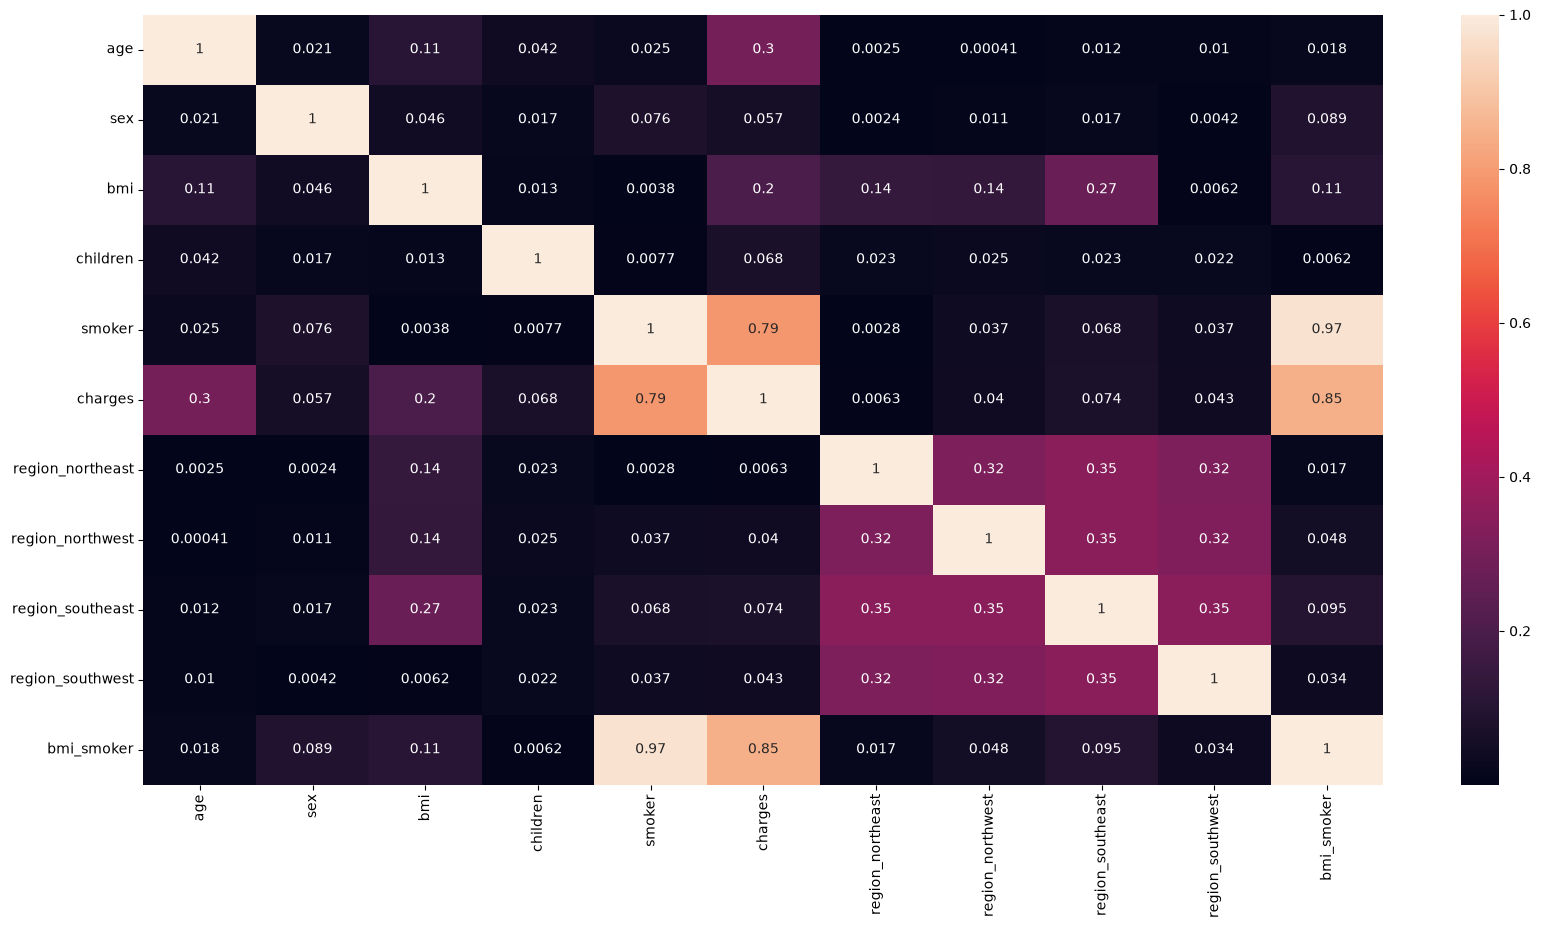

In [7]:
plt.figure(figsize=(20, 10))
sns.heatmap(new_df.corr().abs(),  annot=True)

In [8]:
results_df = pd.DataFrame(columns=["model", "params", "MSE", "MAE"])

## Model comparisons

All models use the same train/test split. Scaling is fitted on the training rows, then applied to the test rows.

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

sk_model = LinearRegression()
sk_model.fit(X_train, y_train)
pred_sk = sk_model.predict(X_test)

mse_val = mean_squared_error(y_test, pred_sk)
mae_val = mean_absolute_error(y_test, pred_sk)

print(f"MSE (test):  {mse_val:.2f}")
print(f"MAE (test):  {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "LinearRegression",
    "params": {},
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

MSE (test):  20919716.75
MAE (test):  2756.90


In [10]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

svr_model = SVR(
    kernel='rbf',
    C=5000,          # штраф за ошибки
    epsilon=0.1,
    gamma='scale'
)

svr_model.fit(X_train, y_train)

pred_svr = svr_model.predict(X_test)

mse_val = mean_squared_error(y_test, pred_svr)
mae_val = mean_absolute_error(y_test, pred_svr)

print(f"MSE (test):  {mse_val:.2f}")
print(f"MAE (test):  {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "SVR",
    "params": {"kernel" : 'rbf', "C" : 5000, "epsilon" : 0.1, "gamma" : 'scale'},
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

MSE (test):  22484023.02
MAE (test):  1840.80


In [11]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

tree_model = DecisionTreeRegressor(random_state=42, max_depth=6)
tree_model.fit(X_train, y_train)

pred_tree = tree_model.predict(X_test)

mse_val = mean_squared_error(y_test, pred_tree)
mae_val = mean_absolute_error(y_test, pred_tree)

print(f"MSE (test):  {mse_val:.2f}")
print(f"MAE (test):  {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "DecisionTreeRegressor",
    "params": {},
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

MSE (test):  23838948.76
MAE (test):  2768.92


In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

rf_model = RandomForestRegressor(
    n_estimators=300,    # количество деревьев
    max_depth=8,         # максимальная глубина деревьев
    random_state=42,
    n_jobs=1
)
rf_model.fit(X_train, y_train)

pred_rf = rf_model.predict(X_test)

mse_val = mean_squared_error(y_test, pred_rf)
mae_val = mean_absolute_error(y_test, pred_rf)

print(f"MSE (test):  {mse_val:.2f}")
print(f"MAE (test):  {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "RandomForestRegressor",
    "params": {"n_estimators" : 300, "max_depth" : 8, "random_state" : 42, "n_jobs" : -1},
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

MSE (test):  19690662.71
MAE (test):  2458.91


In [13]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

gb_model = GradientBoostingRegressor(
    n_estimators=300,     # количество деревьев
    learning_rate=0.05,   # скорость обучения
    max_depth=2,          # глубина отдельных деревьев
    random_state=42
)
gb_model.fit(X_train, y_train)

pred_gb = gb_model.predict(X_test)

mse_val = mean_squared_error(y_test, pred_gb)
mae_val = mean_absolute_error(y_test, pred_gb)

print(f"MSE (test):  {mse_val:.2f}")
print(f"MAE (test):  {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "GradientBoostingRegressor",
    "params": {"n_estimators" : 300, "learning_rate" : 0.05, "max_depth" : 2, "random_state" : 42},
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

MSE (test):  18788572.89
MAE (test):  2407.20


In [14]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

xgb_model = XGBRegressor(
    n_estimators=300,      # количество деревьев
    learning_rate=0.05,    # скорость обучения
    max_depth=2,           # глубина отдельных деревьев
    random_state=42,
    n_jobs=1, objective='reg:squarederror'
)

xgb_model.fit(X_train, y_train)

pred_xgb = xgb_model.predict(X_test)

mse_val = mean_squared_error(y_test, pred_xgb)
mae_val = mean_absolute_error(y_test, pred_xgb)

print(f"MSE (test):  {mse_val:.2f}")
print(f"MAE (test):  {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "XGBRegressor",
    "params": {"n_estimators" : 300, "learning_rate" : 0.05, "max_depth" : 2, "random_state" : 42, "objective" : 'reg:squarederror'},
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

MSE (test):  18416538.70
MAE (test):  2394.17


In [15]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cat_model = CatBoostRegressor(
    iterations=300,       # количество деревьев
    learning_rate=0.05,   # скорость обучения
    depth=2,              # глубина деревьев
    random_seed=42,
    verbose=0, thread_count=1, allow_writing_files=False             # отключаем вывод обучения
)

cat_model.fit(X_train, y_train)

pred_cat = cat_model.predict(X_test)

mse_val = mean_squared_error(y_test, pred_cat)
mae_val = mean_absolute_error(y_test, pred_cat)

print(f"MSE (test):  {mse_val:.2f}")
print(f"MAE (test):  {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "CatBoostRegressor",
    "params": {"n_estimators" : 300, "learning_rate" : 0.05, "max_depth" : 2, "random_state" : 42, "verbose" : 0},
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

MSE (test):  18774378.55
MAE (test):  2356.17


## LightGBM search

Five-fold cross-validation tests 108 combinations. The results table records the parameters selected by cross-validation.

In [16]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lgb_model = LGBMRegressor(random_state=42, verbosity=-1, n_jobs=1)

param_grid = {
    'n_estimators': [100, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 4, 6, 8]
}

grid_search = GridSearchCV(
    estimator=lgb_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=1
)


grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
print("Лучшие параметры:", best_params)

best_model = grid_search.best_estimator_
pred_lgb = best_model.predict(X_test)

mse_val = mean_squared_error(y_test, pred_lgb)
mae_val = mean_absolute_error(y_test, pred_lgb)

print(f"MSE (test): {mse_val:.2f}")
print(f"MAE (test): {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "GridSearchCV",
    "params": best_params,
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
MSE (test): 18756470.33
MAE (test): 2429.74


## Decision tree from scratch

The manual model searches unique feature values and selects splits by weighted mean squared error.

In [17]:
import numpy as np

class DecisionTreeRegressorManual:
    def __init__(self, max_depth=3, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    def fit(self, X, y):
        self.tree = self._build_tree(X, y, depth=0)

    def _build_tree(self, X, y, depth):
        if depth >= self.max_depth or len(y) < self.min_samples_split:
            return np.mean(y)

        n_samples, n_features = X.shape
        best_feat, best_thresh, best_mse = None, None, float('inf')

        for feature_index in range(n_features):
            thresholds = np.unique(X[:, feature_index])
            for t in thresholds:
                left_mask = X[:, feature_index] <= t
                right_mask = X[:, feature_index] > t

                if len(y[left_mask]) == 0 or len(y[right_mask]) == 0:
                    continue

                mse_split = self._mse_split(y[left_mask], y[right_mask])
                if mse_split < best_mse:
                    best_feat = feature_index
                    best_thresh = t
                    best_mse = mse_split

        if best_feat is None:
            return np.mean(y)

        left_mask = X[:, best_feat] <= best_thresh
        right_mask = X[:, best_feat] > best_thresh

        left_subtree = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_subtree = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return {
            "feature": best_feat,
            "threshold": best_thresh,
            "left": left_subtree,
            "right": right_subtree
        }

    def _mse_split(self, left_y, right_y):
        n_left, n_right = len(left_y), len(right_y)
        n_total = n_left + n_right

        mse_left = np.mean((left_y - np.mean(left_y)) ** 2)
        mse_right = np.mean((right_y - np.mean(right_y)) ** 2)

        return (n_left / n_total) * mse_left + (n_right / n_total) * mse_right

    def predict_one(self, x, node):
        if not isinstance(node, dict):
            return node

        feature, threshold = node["feature"], node["threshold"]
        if x[feature] <= threshold:
            return self.predict_one(x, node["left"])
        else:
            return self.predict_one(x, node["right"])

    def predict(self, X):
        return np.array([self.predict_one(x, self.tree) for x in X])

In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = new_df.drop(columns=["charges"]).to_numpy(dtype=float)
y = new_df["charges"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

manual_tree = DecisionTreeRegressorManual(max_depth=6)
manual_tree.fit(X_train, y_train)

pred_manual = manual_tree.predict(X_test)

mse_val = mean_squared_error(y_test, pred_manual)
mae_val = mean_absolute_error(y_test, pred_manual)

print(f"MSE (test):  {mse_val:.2f}")
print(f"MAE (test):  {mae_val:.2f}")

results_df = pd.concat([results_df, pd.DataFrame([{
    "model": "DecisionTreeRegressorManual",
    "params": {},
    "MSE": mse_val,
    "MAE": mae_val
}])], ignore_index=True)

MSE (test):  22844260.90
MAE (test):  2728.20


## Results

These metrics use one test split. Compare candidates using cross-validation and reserve a separate test set for final evaluation.

In [19]:
results_df

,model,params,MSE,MAE
0,LinearRegression,{},20919716.751169,2756.89866
1,SVR,"{'kernel': 'rbf', 'C': 5000, 'epsilon': 0.1, '...",22484023.021056,1840.80238
2,DecisionTreeRegressor,{},23838948.760947,2768.916608
3,RandomForestRegressor,"{'n_estimators': 300, 'max_depth': 8, 'random_...",19690662.713459,2458.907293
4,GradientBoostingRegressor,"{'n_estimators': 300, 'learning_rate': 0.05, '...",18788572.891295,2407.197494
5,XGBRegressor,"{'n_estimators': 300, 'learning_rate': 0.05, '...",18416538.696146,2394.167603
6,CatBoostRegressor,"{'n_estimators': 300, 'learning_rate': 0.05, '...",18774378.54603,2356.171349
7,GridSearchCV,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",18756470.326014,2429.739492
8,DecisionTreeRegressorManual,{},22844260.895156,2728.195637
